# Task 3 — Sound Data Collection and Processing

Each member recorded two phrases, **"Yes, approve"** and **"Confirm transaction"**. This notebook

1. checks every member has both phrases,
2. plots each recording as a waveform and a spectrogram, with interpretation,
3. applies three augmentations (pitch shift, time stretch, background noise),
4. extracts MFCCs, spectral roll-off, energy and other features into `audio_features.csv`.

The processing code lives in `src/preprocess_audio.py`, so the voiceprint model and the command-line app extract features from a new voice sample in exactly the same way.

In [13]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
from IPython.display import Audio, display

import preprocess_audio as ap

plt.rcParams["figure.dpi"] = 100
print("Sample rate:", ap.SR, "Hz | raw folder:", ap.RAW_DIR.relative_to(ROOT))

Sample rate: 16000 Hz | raw folder: data/raw/audio


## 1. Recording inventory

Recordings live in `data/raw/audio/` (kept out of Git, as biometric data) and follow one naming rule, `<member_id>_<phrase>.wav` (e.g. `member01_yes_approve.wav`). The member IDs are the same as in the image pipeline, so the voice check can confirm the voice belongs to the person the face model recognised. All audio is resampled to 16 kHz mono, leading and trailing silence is trimmed, and each clip is peak-normalised so loudness differences between phones don't dominate the features.

In [14]:
recordings = ap.list_recordings()
coverage = ap.check_coverage(recordings)   # raises an error if anyone is missing a phrase
display(coverage)

clips = {(r.member_id, r.phrase, r.take): ap.load_audio(r.path) for r in recordings.itertuples()}
members = sorted(recordings["member_id"].unique())
print(f"{len(members)} members, {len(recordings)} recordings")

phrase,yes_approve,confirm_transaction
member_id,,
member01,1,1
member02,1,1
member03,1,1
member04,1,1


4 members, 8 recordings


## 2. Waveforms and spectrograms per member

The **waveform** shows amplitude over time: each burst is a word or syllable and the gaps are pauses. The **mel spectrogram** shows which frequencies carry energy over time (brighter = more energy). Horizontal bands are the harmonics and formants of the voice, which differ between speakers; that difference is what the voiceprint model learns.

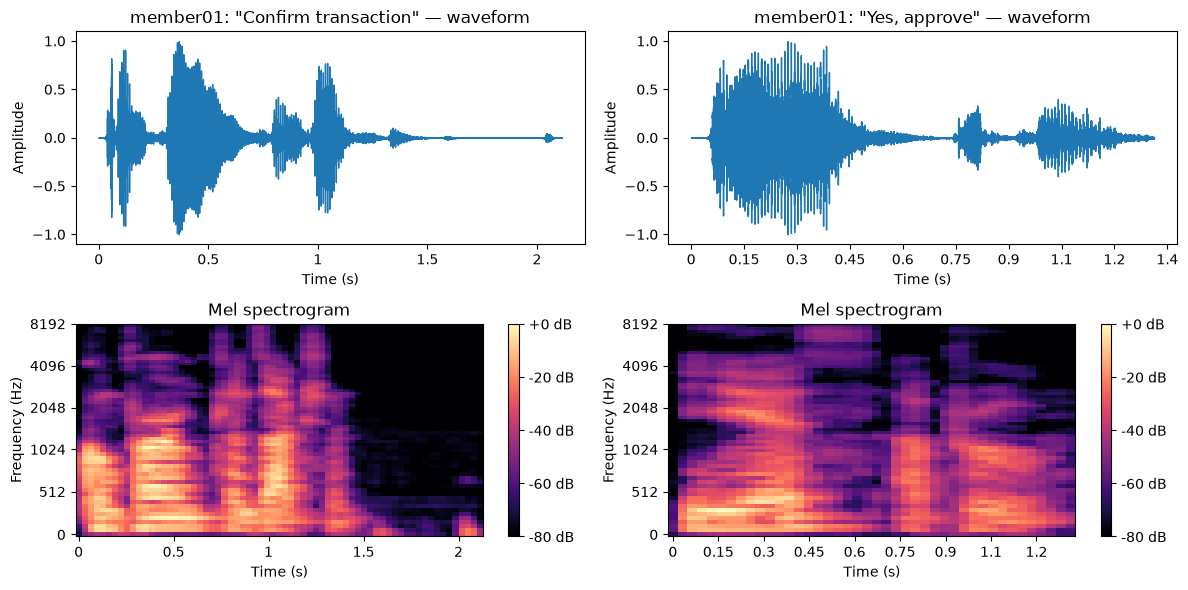

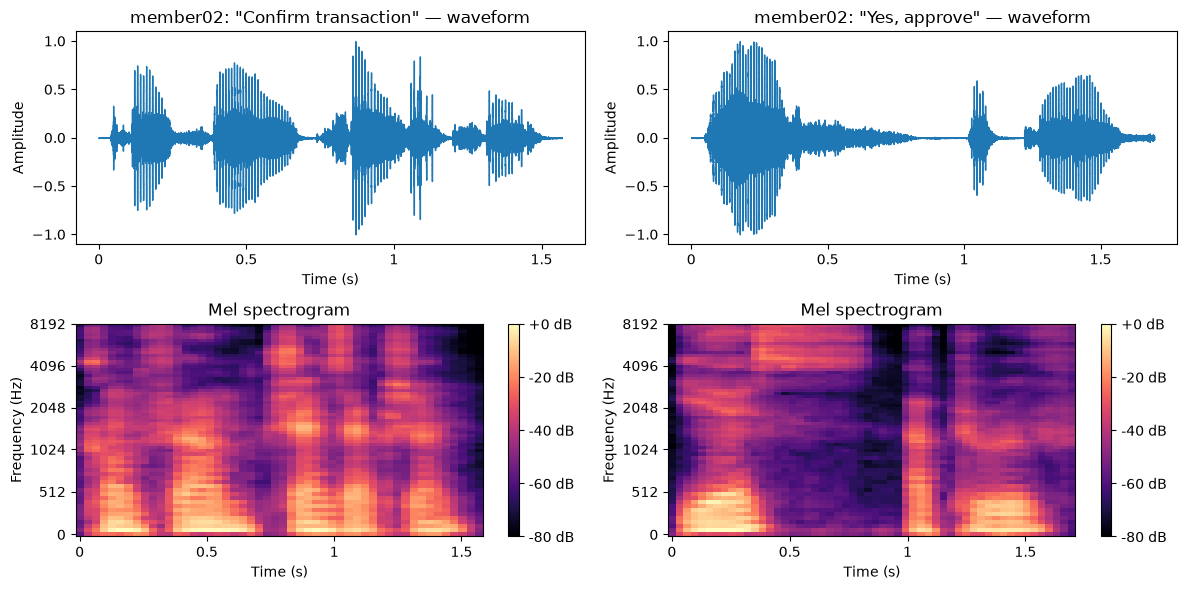

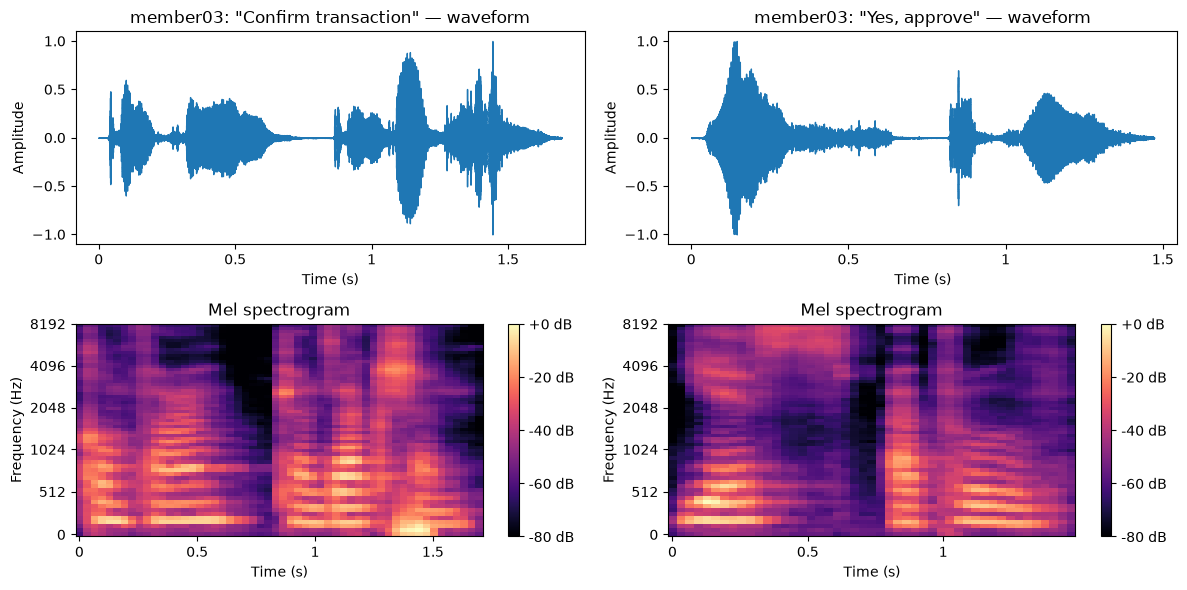

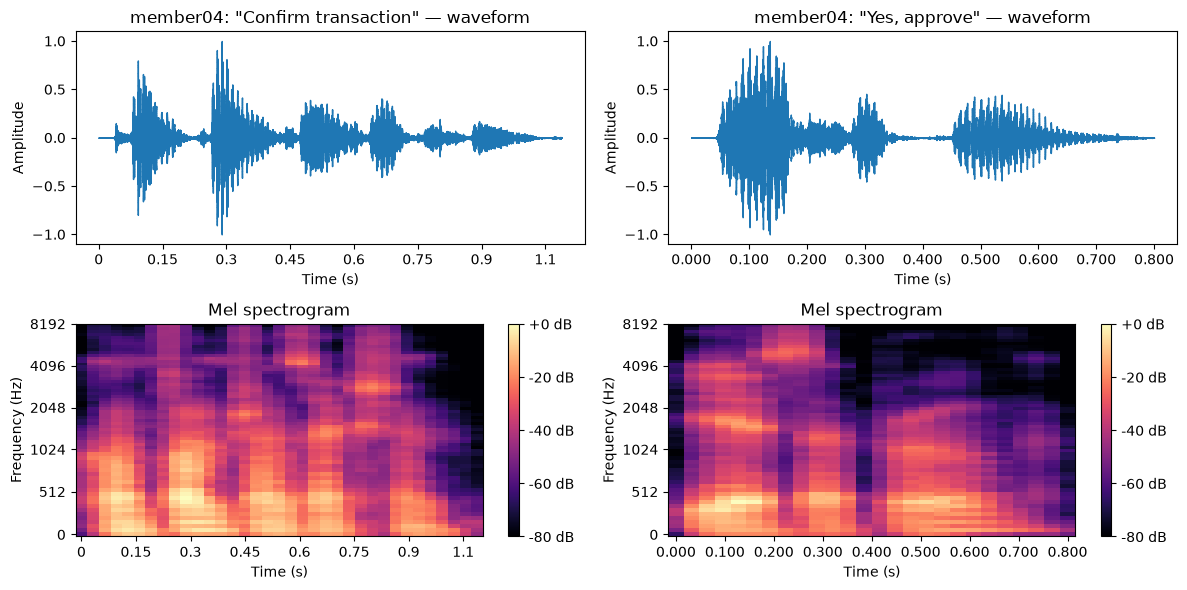

In [15]:
def plot_member(member):
    takes = recordings[(recordings["member_id"] == member) & (recordings["take"] == 1)]
    fig, axes = plt.subplots(2, len(takes), figsize=(6 * len(takes), 6), squeeze=False)
    for col, r in enumerate(takes.itertuples()):
        y = clips[(r.member_id, r.phrase, r.take)]
        librosa.display.waveshow(y, sr=ap.SR, ax=axes[0, col], color="tab:blue")
        axes[0, col].set(title=f"{member}: \"{ap.PHRASES[r.phrase]}\" — waveform",
                         xlabel="Time (s)", ylabel="Amplitude")
        S = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=ap.SR, n_mels=64), ref=np.max)
        img = librosa.display.specshow(S, sr=ap.SR, x_axis="time", y_axis="mel", ax=axes[1, col])
        axes[1, col].set(title="Mel spectrogram", xlabel="Time (s)", ylabel="Frequency (Hz)")
        fig.colorbar(img, ax=axes[1, col], format="%+2.0f dB")
    fig.tight_layout()
    plt.show()

for m in members:
    plot_member(m)

### Interpretation

The table below measures what the plots show, so the comparison between members is based on numbers rather than eyeballing:

* **duration** — how long each person takes to say the phrase (speaking rate),
* **pitch (median F0)** — estimated with the pYIN algorithm; deeper voices have a lower value,
* **spectral centroid** — the "brightness" of the voice; it tends to follow pitch and how the speaker articulates,
* **silence ratio** — share of frames with very low energy, i.e. the pauses visible in the waveform.

In [16]:
def describe_clip(y):
    f0, voiced, _ = librosa.pyin(y, fmin=65, fmax=400, sr=ap.SR)
    rms = librosa.feature.rms(y=y)[0]
    return {
        "duration_s": len(y) / ap.SR,
        "median_pitch_hz": float(np.nanmedian(f0)) if np.any(voiced) else np.nan,
        "centroid_hz": float(librosa.feature.spectral_centroid(y=y, sr=ap.SR).mean()),
        "silence_ratio": float((rms < 0.1 * rms.max()).mean()),
    }

summary = pd.DataFrame([{"member_id": m, "phrase": p, **describe_clip(y)}
                        for (m, p, t), y in clips.items() if t == 1]).round(3)
display(summary)

per_member = summary.groupby("member_id")[["duration_s", "median_pitch_hz", "centroid_hz"]].mean()
print(f"Lowest voice:  {per_member.median_pitch_hz.idxmin()} ({per_member.median_pitch_hz.min():.0f} Hz)")
print(f"Highest voice: {per_member.median_pitch_hz.idxmax()} ({per_member.median_pitch_hz.max():.0f} Hz)")
print(f"Fastest speaker: {per_member.duration_s.idxmin()} | slowest: {per_member.duration_s.idxmax()}")
by_phrase = summary.groupby("phrase").duration_s.mean()
print(f"'Confirm transaction' is {by_phrase['confirm_transaction'] / by_phrase['yes_approve']:.1f}x "
      "as long as 'Yes, approve' on average (more syllables).")

,member_id,phrase,duration_s,median_pitch_hz,centroid_hz,silence_ratio
0,member01,confirm_transaction,2.112,102.291,1008.910,0.448
1,member01,yes_approve,1.312,111.227,1238.209,0.262
2,member02,confirm_transaction,1.568,99.092,1760.653,0.040
3,member02,yes_approve,1.696,99.379,2707.358,0.315
4,member03,confirm_transaction,1.696,198.185,1477.123,0.148
5,member03,yes_approve,1.472,193.658,2691.039,0.255
6,member04,confirm_transaction,1.088,81.423,1226.271,0.114
7,member04,yes_approve,0.800,85.028,1242.127,0.154


Lowest voice:  member04 (83 Hz)
Highest voice: member03 (196 Hz)
Fastest speaker: member04 | slowest: member01
'Confirm transaction' is 1.2x as long as 'Yes, approve' on average (more syllables).


**Reading the plots and table:** member03 has a clearly higher voice (≈196 Hz median pitch) than the other three, who sit close together between ≈83 Hz (member04, the lowest) and ≈111 Hz (member01). Because three members share a similar pitch range, pitch alone can't tell them apart; the voiceprint model relies on the MFCCs, which capture the overall shape of each voice's spectrum and not just its pitch.

Speaking rate varies a lot: member04 is the fastest (0.8 s for "Yes, approve", 1.1 s for "Confirm transaction"), while member01 is the slowest at 2.1 s for "Confirm transaction". member01's clip also has the most silence (45% of frames), visible as long gaps between words in the waveform. The "Yes, approve" clips of member02 and member03 have a much higher spectral centroid (≈2.7 kHz vs ≈1.2–1.5 kHz for the rest) because both speakers draw out the "s" in "yes": it shows as bright energy from 2 to 8 kHz in the spectrogram and as a long low-amplitude tail in the waveform. The "p" in "approve" appears as a thin vertical streak across all frequencies, a short burst of air just before the final word. The pauses between words are dark in the spectrograms, so the recordings themselves are clean; the background-noise augmentation prepares the model for noisier conditions than the ones we recorded in.

In the spectrograms most energy sits below about 1 kHz (the pitch and its first harmonics). The "Yes, approve" clips of member02 and member03 have a much higher spectral centroid (≈2.7 kHz vs ≈1.2–1.5 kHz for the rest), meaning more high-frequency energy from sharper "s" sounds or background hiss in those recordings. Recording conditions differed between members, which is one reason we add background-noise augmentation.

## 3. Augmentation

Each recording gets three augmentations, so the voiceprint model sees realistic variation and does not overfit to a single recording:

| Augmentation | Setting | What it simulates |
|---|---|---|
| Pitch shift | +2 semitones | Voice slightly higher (tired, excited, cold) |
| Time stretch | 1.15× speed, pitch unchanged | Speaking faster |
| Background noise | white noise at 20 dB SNR | A noisy room or a cheap microphone |

Below, one recording is shown in its original form and after each augmentation.

/home/rcaa/miniconda3/lib/python3.14/site-packages/librosa/effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
/home/rcaa/miniconda3/lib/python3.14/site-packages/librosa/effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(


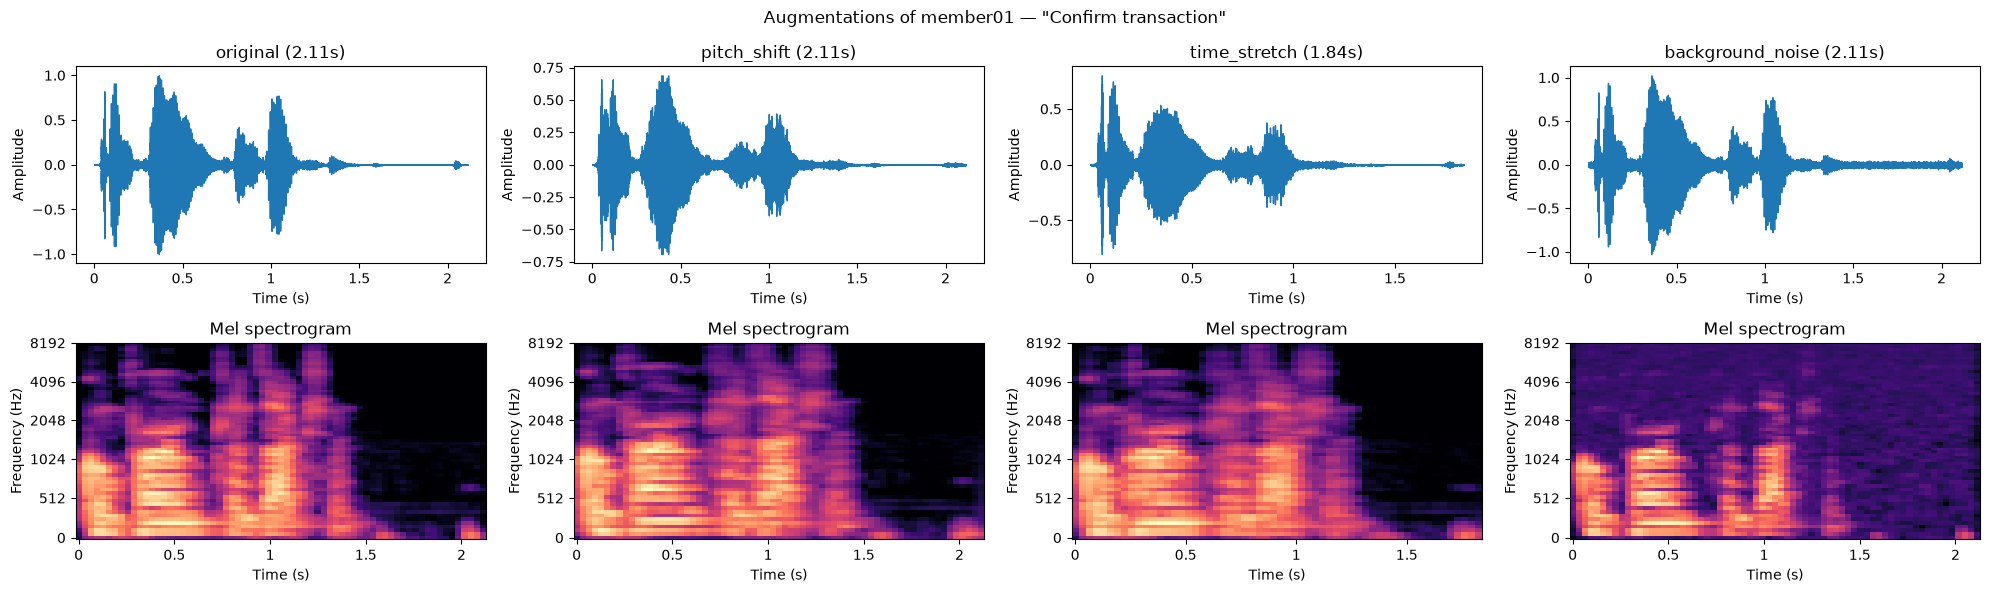

In [17]:
example_key = next(iter(clips))
y0 = clips[example_key]
versions = {"original": y0, **{n: fn(y0, ap.SR) for n, fn in ap.AUGMENTATIONS.items()}}

fig, axes = plt.subplots(2, 4, figsize=(20, 6))
for col, (name, y) in enumerate(versions.items()):
    librosa.display.waveshow(y, sr=ap.SR, ax=axes[0, col])
    axes[0, col].set(title=f"{name} ({len(y)/ap.SR:.2f}s)", xlabel="Time (s)", ylabel="Amplitude")
    S = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=ap.SR, n_mels=64), ref=np.max)
    librosa.display.specshow(S, sr=ap.SR, x_axis="time", y_axis="mel", ax=axes[1, col])
    axes[1, col].set(title="Mel spectrogram", xlabel="Time (s)", ylabel="Frequency (Hz)")
fig.suptitle(f"Augmentations of {example_key[0]} — \"{ap.PHRASES[example_key[1]]}\"")
fig.tight_layout()
plt.show()


The pitch-shifted spectrogram has the same shape with the harmonic bands moved up; the time-stretched clip is shorter but keeps its bands at the same height; the noisy clip shows a grainy floor of energy across all frequencies, filling the pauses that were dark in the original.

## 4. Feature extraction → `data/processed/audio_features.csv`

Every clip (original + 3 augmentations) becomes one row of fixed-length features:

| Feature | Columns | Why |
|---|---|---|
| MFCC 1–13 (mean, std) | 26 | Shape of the vocal tract: the core voiceprint |
| Spectral roll-off (mean, std) | 2 | Frequency below which 85% of energy lies |
| Spectral centroid (mean, std), bandwidth | 3 | Brightness and spread of the voice |
| RMS energy (mean, std) | 2 | Loudness and its variation |
| Zero-crossing rate | 1 | Noisiness / voiced vs unvoiced sounds |
| Duration | 1 | Speaking rate |

`member_id` is the label for the voiceprint model (`src/train_voice_model.py`), and `source_file` keeps a recording and its augmented copies on the same side of the train/test split so the scores are honest.

In [18]:
features = ap.process_recordings(recordings)
ap.FEATURES_CSV.parent.mkdir(parents=True, exist_ok=True)
features.to_csv(ap.FEATURES_CSV, index=False)

print("Shape:", features.shape)
print("Missing values:", int(features.isna().sum().sum()))
display(features.groupby(["member_id", "augmentation"]).size().unstack())
display(features.head())

Shape: (32, 40)
Missing values: 0


/home/rcaa/miniconda3/lib/python3.14/site-packages/numba/np/ufunc/dufunc.py:303: RuntimeWarning: invalid value encountered in cast
  return super().__call__(*args, **kws)


augmentation,background_noise,original,pitch_shift,time_stretch
member_id,,,,
member01,2,2,2,2
member02,2,2,2,2
member03,2,2,2,2
member04,2,2,2,2


,sample_id,member_id,phrase,source_file,augmentation,duration_s,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,...,mfcc_13_mean,mfcc_13_std,rolloff_mean,rolloff_std,centroid_mean,centroid_std,bandwidth_mean,rms_energy_mean,rms_energy_std,zcr_mean
0,member01_confirm_transaction_original,member01,confirm_transaction,member01_confirm_transaction.wav,original,2.1120,-347.165924,157.377884,125.852409,78.316330,...,-1.562627,11.514930,1855.993470,1359.757077,1008.910374,626.800277,1106.200161,0.084644,0.089138,0.076310
1,member01_confirm_transaction_pitch_shift,member01,confirm_transaction,member01_confirm_transaction.wav,pitch_shift,2.1120,-355.109711,158.252228,119.703552,69.380501,...,-7.153045,14.050685,1854.594216,1208.770069,1045.076946,575.680006,1131.716879,0.060635,0.064243,0.084305
2,member01_confirm_transaction_time_stretch,member01,confirm_transaction,member01_confirm_transaction.wav,time_stretch,1.8365,-351.930145,151.423721,124.466736,72.720268,...,-1.107726,9.537520,1680.360991,1153.452796,939.507286,522.663175,1086.355856,0.064417,0.064067,0.068705
3,member01_confirm_transaction_background_noise,member01,confirm_transaction,member01_confirm_transaction.wav,background_noise,2.1120,-154.886668,52.606036,49.543601,45.738792,...,-2.786804,7.961738,5127.915112,1911.189654,2698.477217,1061.628565,2174.394445,0.088502,0.086225,0.252543
4,member01_yes_approve_original,member01,yes_approve,member01_yes_approve.wav,original,1.3120,-240.736771,93.623505,130.566238,49.382156,...,-6.045508,10.601850,2410.714286,1947.678524,1238.208907,796.254545,1284.099741,0.129268,0.118649,0.069103


In [19]:
feature_cols = [c for c in features.columns if c not in ("sample_id", "member_id", "phrase", "source_file", "augmentation")]
display(features.groupby("member_id")[["mfcc_1_mean", "mfcc_2_mean", "rolloff_mean",
                                    "centroid_mean", "rms_energy_mean"]].mean().round(2))

,mfcc_1_mean,mfcc_2_mean,rolloff_mean,centroid_mean,rms_energy_mean
member_id,,,,,
member01,-257.60,107.68,2880.16,1486.40,0.10
member02,-202.87,61.61,4338.14,2368.37,0.10
member03,-212.19,69.32,4184.38,2255.27,0.09
member04,-202.14,115.61,3068.19,1567.54,0.10


### Do the features separate the speakers?

A 2-D PCA projection of the standardised features gives a quick check: if each member's points form their own cluster, the voiceprint model has something to learn.

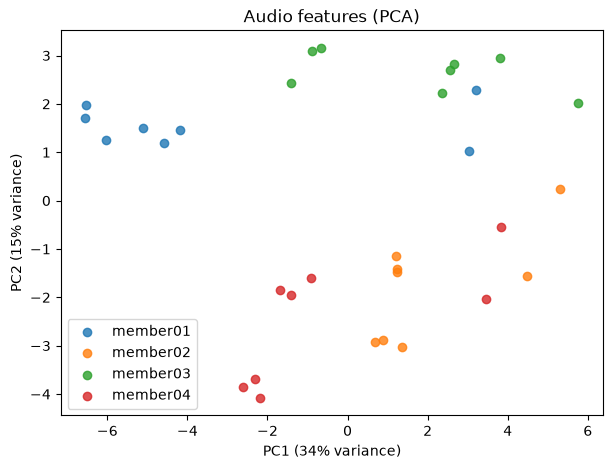

In [20]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

X = StandardScaler().fit_transform(features[feature_cols])
pca = PCA(n_components=2, random_state=ap.SEED)
Z = pca.fit_transform(X)

fig, ax = plt.subplots(figsize=(7, 5))
for m in members:
    mask = features["member_id"] == m
    ax.scatter(Z[mask, 0], Z[mask, 1], label=m, alpha=0.8)
ax.set(title="Audio features (PCA)",
       xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%} variance)",
       ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%} variance)")
ax.legend()
plt.show()

## 5. Unauthorized sample (for the system demo)

Recordings from someone outside the group go in `data/raw/audio/unauthorized/`. They are processed with the same feature function but saved separately to `data/processed/audio_features_unauthorized.csv`, so they never enter the training data and can be used to show the voice check rejecting an unknown speaker.

In [21]:
unauth = ap.process_unauthorized()
if unauth.empty:
    print("No files in data/raw/audio/unauthorized/ yet.")
else:
    unauth.to_csv(ap.UNAUTH_CSV, index=False)
    display(unauth[["source_file", "duration_s", "mfcc_1_mean", "rolloff_mean", "rms_energy_mean"]])

,source_file,duration_s,mfcc_1_mean,rolloff_mean,rms_energy_mean
0,outsider_confirm_transaction.wav,3.840,-252.126526,3876.420455,0.106833
1,outsider_yes_approve.wav,3.328,-385.513458,4614.583333,0.041735
